# Exercise 2 · XAI — explaining the model with SHAP

**Question:** On which features is the model's prediction based?

The Random Forest from `model.ipynb` is a black box: 300 trees vote, and nobody can read why one employee gets a high risk score. SHAP opens it up.

## 1 What is SHAP?
SHAP (SHapley Additive exPlanations) splits a prediction fairly among the features.

- **Start:** the model's average risk score across all employees (the *base value*).
- **Each feature** then pushes this one employee's score **up** (red) or **down** (blue).
- **End:** base value + all pushes = the model's risk score for this employee. Nothing is left unexplained.

The idea comes from game theory: a team wins a prize, and each player gets a share that matches their contribution. Here the "players" are the features and the "prize" is the prediction.

One method gives both views:
- **Local:** why did *this employee* get this score?
- **Global:** which features matter most *across all employees*? (the average size of the pushes)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

SEED = 42
THRESHOLD = 0.44  # tuned cut-off from model.ipynb

/Users/jonas/Desktop/aibis/exercise 2/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2 Rebuild the model
Same data preparation, split and Random Forest settings as in `model.ipynb`.

In [ ]:
raw = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv").drop(
    columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])
y = (raw.pop("Attrition") == "Yes").astype(int)
df = raw.copy()
df["OverTime"] = (df["OverTime"] == "Yes").astype(int)
df["Gender"] = (df["Gender"] == "Male").astype(int)
df["BusinessTravel"] = df["BusinessTravel"].map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
X = pd.get_dummies(df, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3, class_weight="balanced",
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
proba = pd.Series(rf.predict_proba(X_test)[:, 1], index=X_test.index)

## 3 Compute SHAP values
`TreeExplainer` is SHAP's exact and fast method for tree models. We explain the 294 test employees, whom the model has never seen.

The model uses 47 columns because each category (e.g. every job role) has its own column. We add these back together, so each of the 30 original features gets **one** SHAP value.

In [ ]:
sv = shap.TreeExplainer(rf)(X_test)[..., 1]  # class 1 = "left"

groups = {c: [c] if c in X else [d for d in X.columns if d.startswith(c + "_")] for c in raw.columns}
exp = shap.Explanation(
    values=np.column_stack([sv.values[:, X.columns.get_indexer(cols)].sum(axis=1) for cols in groups.values()]),
    base_values=sv.base_values,
    data=df.loc[X_test.index].apply(pd.to_numeric, errors="coerce").values,  # numbers, used for colouring
    display_data=raw.loc[X_test.index].values,                              # readable values, used as labels
    feature_names=list(groups),
)
print(f"base value (average risk score): {exp.base_values[0]:.2f}")
print(f"check: base value + SHAP values = model output for all employees: "
      f"{np.allclose(exp.base_values + exp.values.sum(axis=1), proba.values, atol=1e-6)}")

base value (average risk score): 0.50
check: base value + SHAP values = model output for all employees: True


The base value is 0.50, not the real attrition rate of 16 %, because the model was trained to give leavers extra weight. So risk scores are for **ranking** employees. They are not exact probabilities.

## 4 Global explanation — what drives the model overall?
**Bar chart:** average size of each feature's push, in risk-score points. Longer bar = more important.

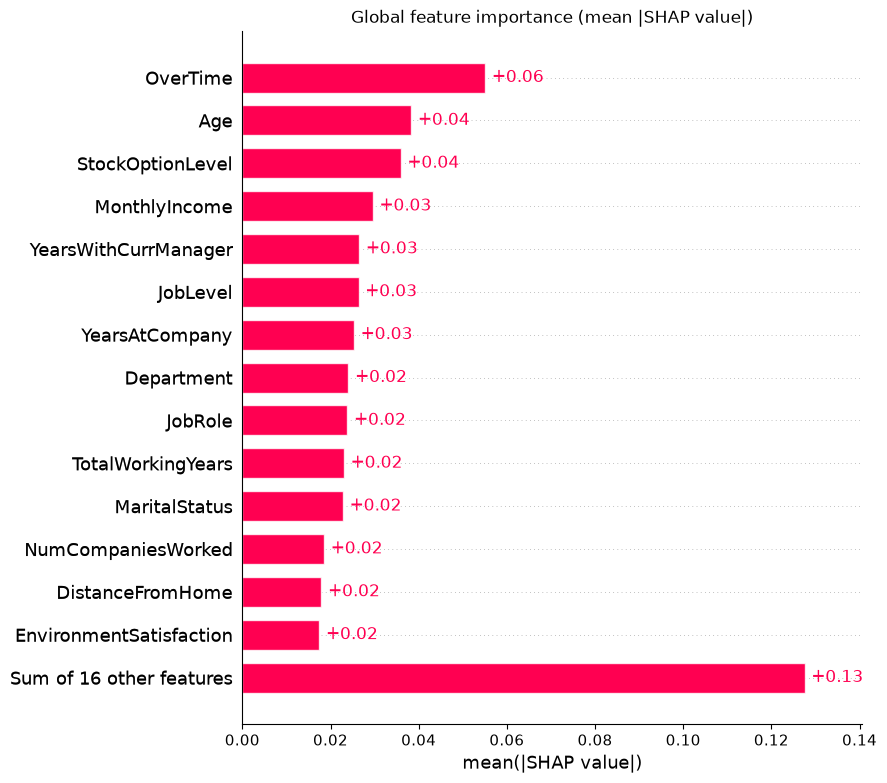

In [ ]:
shap.plots.bar(exp, max_display=15, show=False)
plt.title("Global feature importance (mean |SHAP value|)")
plt.show()

**Beeswarm chart:** one dot per employee and feature.
- Position: right of the line = raises the risk, left = lowers it.
- Colour: red = high feature value (large numeric value), blue = low. Grey = category without an order (e.g. job role).

/Users/jonas/Desktop/aibis/exercise 2/.venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


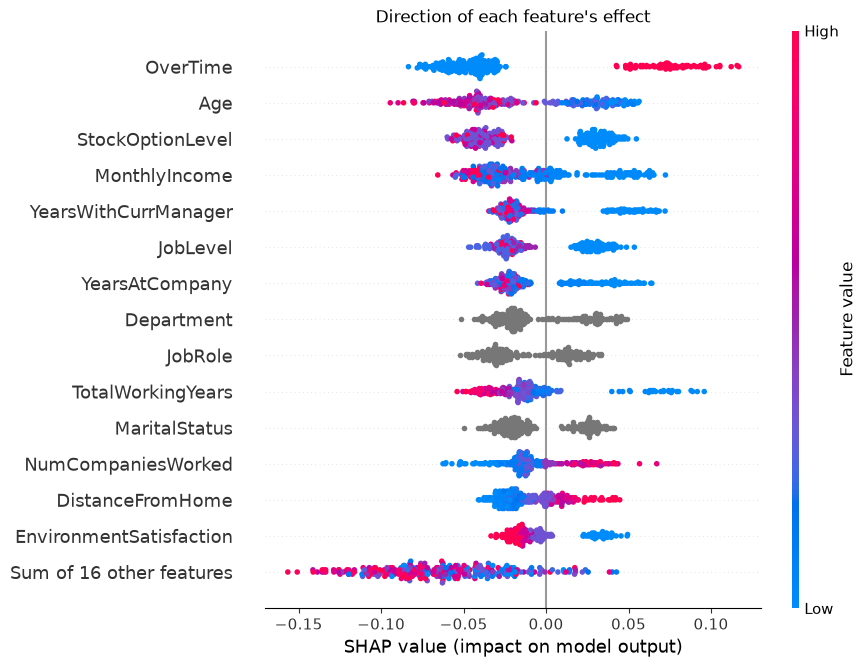

In [ ]:
shap.plots.beeswarm(exp, max_display=15, show=False)
plt.title("Direction of each feature's effect")
plt.show()

In [ ]:
importance = pd.Series(np.abs(exp.values).mean(axis=0), index=exp.feature_names).sort_values(ascending=False)
blocks = {
    "Seniority & pay": ["MonthlyIncome", "JobLevel", "TotalWorkingYears", "Age"],
    "Tenure": ["YearsAtCompany", "YearsInCurrentRole", "YearsWithCurrManager", "YearsSinceLastPromotion"],
    "Overtime": ["OverTime"],
    "Stock options & marital status": ["StockOptionLevel", "MaritalStatus"],
    "Satisfaction & involvement": ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
                                   "RelationshipSatisfaction", "JobInvolvement"],
    "Job role & department": ["JobRole", "Department"],
    "Rates (daily/hourly/monthly)": ["DailyRate", "HourlyRate", "MonthlyRate"],
}
print("Top 10 features:\n" + importance.head(10).round(4).to_string())
print("\nImportance per group of related features:\n"
      + pd.Series({b: importance[f].sum() for b, f in blocks.items()}).sort_values(ascending=False).round(4).to_string())

Top 10 features:
OverTime                0.0551
Age                     0.0383
StockOptionLevel        0.0359
MonthlyIncome           0.0296
YearsWithCurrManager    0.0265
JobLevel                0.0264
YearsAtCompany          0.0253
Department              0.0241
JobRole                 0.0238
TotalWorkingYears       0.0231

Importance per group of related features:
Seniority & pay                   0.1174
Tenure                            0.0721
Satisfaction & involvement        0.0608
Stock options & marital status    0.0588
Overtime                          0.0551
Job role & department             0.0479
Rates (daily/hourly/monthly)      0.0301


**What the global view shows**
- **Overtime is the single most important feature.** Working overtime clearly raises the risk score, not working overtime lowers it.
- **Age, stock options and monthly income follow.** Low values (blue dots on the right) raise the risk: young, no stock options, low pay.
- **By group, seniority and pay matter most**, then tenure, satisfaction, and stock options with marital status. Related features share their importance, so the group view is the fairer one.
- **No single feature decides.** Each one moves the score by a few points; a high risk score comes from many pushes in the same direction.
- **Same picture as the EDA**, which found the same risk factors. The model has learned patterns that are visible in the data.

**A closer look at three features.** Each dot is one employee. Above the dashed line = the feature raises the risk, below = it lowers it.

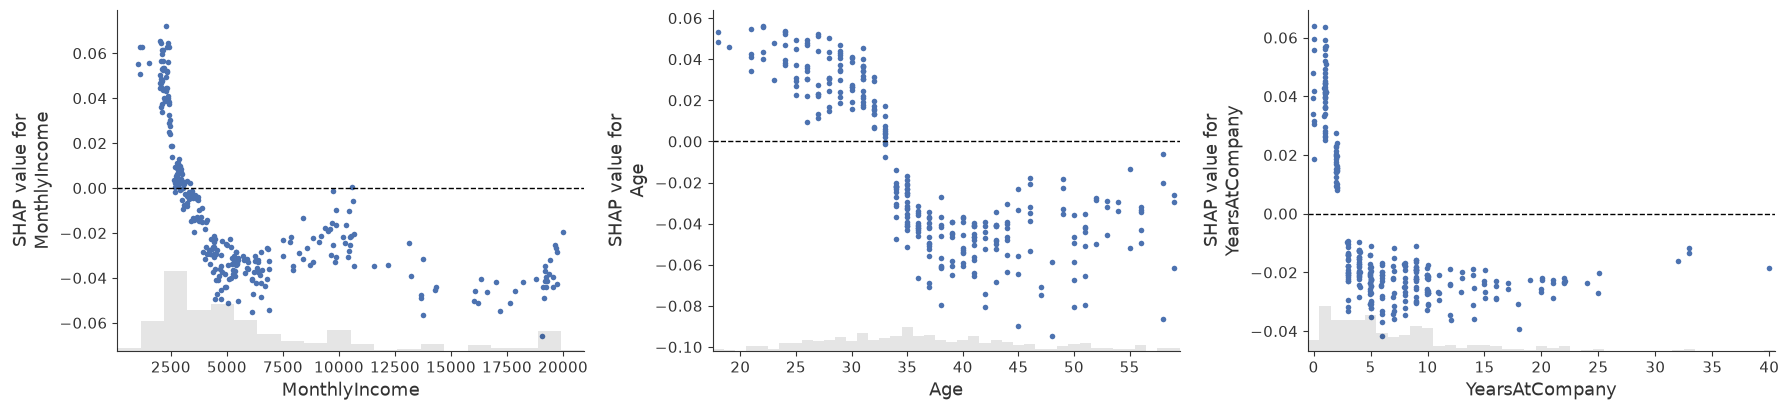

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, f in zip(axes, ["MonthlyIncome", "Age", "YearsAtCompany"]):
    shap.plots.scatter(exp[:, f], ax=ax, show=False, color="#4c72b0")
    ax.axhline(0, ls="--", c="k", lw=1)
fig.tight_layout()

The effects are not straight lines, they have tipping points:
- **Monthly income:** below about 3,000 the risk goes up; above it, income lowers the risk.
- **Age:** under about 33 raises the risk, older lowers it.
- **Years at company:** the first two years raise the risk; from year three on it drops.

## 5 Local explanations — three employees
Picked from the test set so that they differ:
1. **Clear leaver:** left, and got the highest risk score among those who left.
2. **Clear stayer:** stayed, and got the lowest risk score.
3. **Border case:** risk score closest to the cut-off of 0.44.

**Reading a waterfall chart.** Start at the bottom with the base value. Each bar is one feature: red pushes the risk up, blue pushes it down. The top value `f(x)` is this employee's risk score.


Clear leaver: risk score 0.95 (flagged), actually left
  TotalWorkingYears=1 (+0.065) | MonthlyIncome=2121 (+0.053) | OverTime=Yes (+0.051) | YearsWithCurrManager=0 (+0.051) | YearsAtCompany=1 (+0.049) | Age=19 (+0.046)


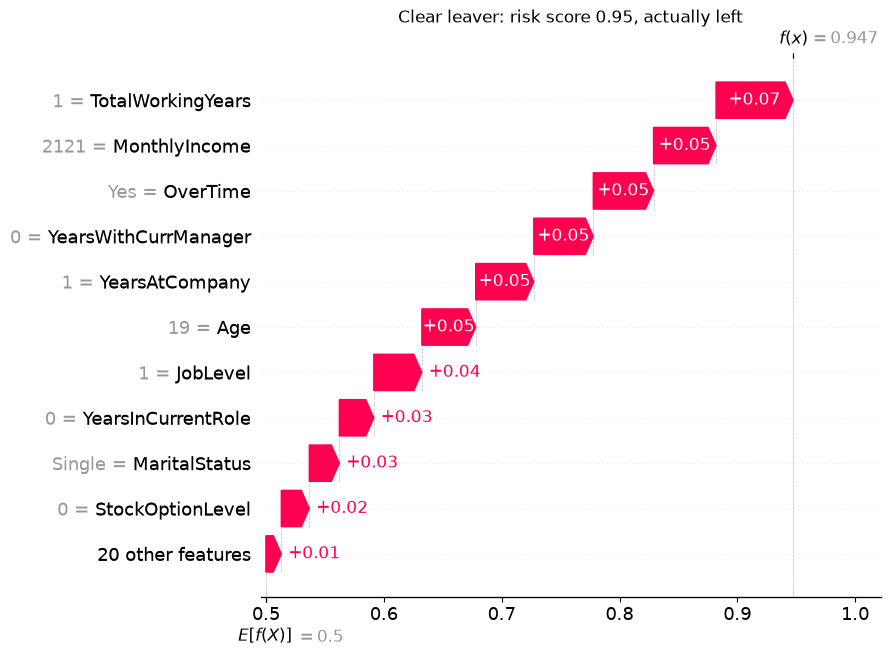


Clear stayer: risk score 0.05 (not flagged), actually stayed
  StockOptionLevel=2 (-0.040) | OverTime=No (-0.037) | MonthlyIncome=5470 (-0.033) | NumCompaniesWorked=0 (-0.032) | YearsAtCompany=9 (-0.031) | JobRole=Research Scientist (-0.029)


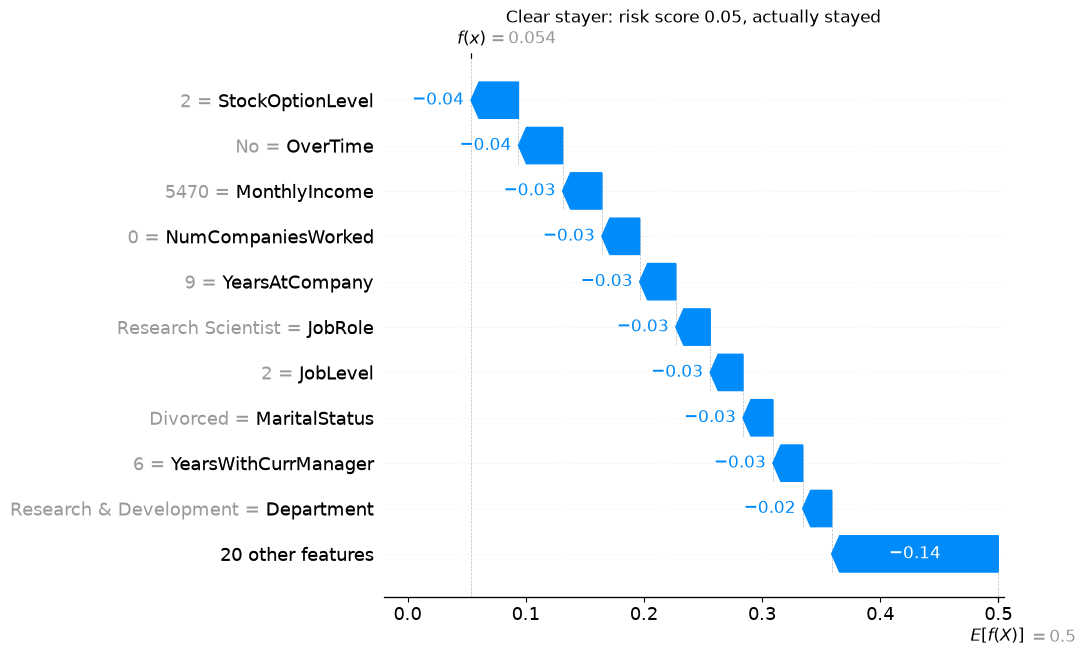


Border case: risk score 0.44 (flagged), actually stayed
  YearsWithCurrManager=0 (+0.062) | OverTime=No (-0.061) | Age=21 (+0.042) | JobRole=Research Scientist (-0.031) | StockOptionLevel=0 (+0.031) | JobLevel=1 (+0.030)


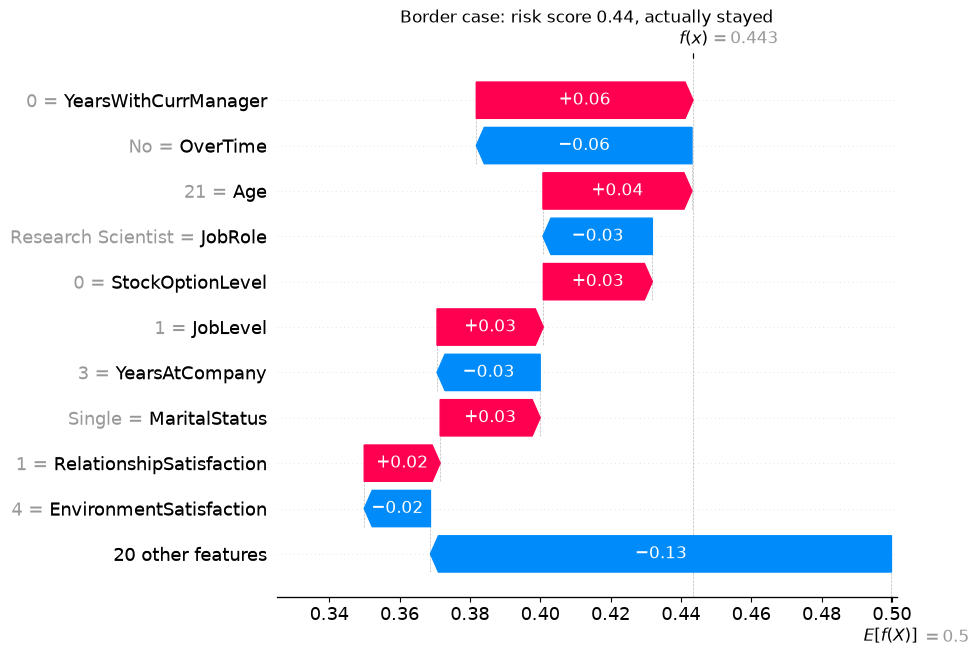

In [ ]:
cases = {
    "Clear leaver": proba[y_test == 1].idxmax(),
    "Clear stayer": proba[y_test == 0].idxmin(),
    "Border case": (proba - THRESHOLD).abs().idxmin(),
}
for name, idx in cases.items():
    i = X_test.index.get_loc(idx)
    e = exp[i]
    actual = "left" if y_test[idx] else "stayed"
    flag = "flagged" if proba[idx] >= THRESHOLD else "not flagged"
    print(f"\n{name}: risk score {proba[idx]:.2f} ({flag}), actually {actual}")
    order = np.argsort(-np.abs(e.values))[:6]
    print("  " + " | ".join(f"{e.feature_names[j]}={e.display_data[j]} ({e.values[j]:+.3f})" for j in order))
    shap.plots.waterfall(e, max_display=11, show=False)
    plt.title(f"{name}: risk score {proba[idx]:.2f}, actually {actual}")
    plt.show()

**What the three cases show**

1. **Clear leaver (risk score 0.95, left).** 19 years old, first year of work and first year at the company, monthly income 2,121, works overtime, brand-new manager. Every important feature pushes the same way: up.
2. **Clear stayer (risk score 0.05, stayed).** No overtime, stock option level 2, monthly income 5,470, 9 years at the company, never worked anywhere else. Every important feature pushes down.
3. **Border case (risk score 0.44, stayed).** The signals pull in both directions. Up: new manager, 21 years old, no stock options, entry level, single. Down: no overtime, Research Scientist, already 3 years at the company. They roughly cancel out, so the model is unsure. No overtime is what keeps this score down the most.

## 6 Takeaways

**On which features is the prediction based?**
- Mainly on **overtime**, **seniority and pay** (age, income, job level, working years), **tenure** (years at the company and with the current manager) and **stock options**.
- Satisfaction scores, job role and department add smaller pushes.
- The picture matches the EDA, which is a reason to trust the explanation.

**What management can act on**
- Overtime.
- Pay and stock options at entry level.
- Support in the first two years.
- Changes of manager.

**Limits**
- SHAP explains the **model**, not the true causes. Overtime raises the model's risk score; that does not prove that cutting overtime keeps people.
- The model is only moderately accurate (ROC-AUC 0.79). SHAP explains wrong predictions just as confidently as right ones.
- Related features (e.g. job level and income) share their importance, so read them as a group.
- Risk scores are for ranking, not exact probabilities.